# Validate linear summation (metamodel vs dynamic)

Compare offshore-driven **dynamic SnapWave** to the **reconstructed metamodel**.

- **`mm.reconstruct(..., spectral=True)`** — partitions ``0``–``3`` per goal, wavespectra linear sum (validation vs dynamic).
- **`mm.reconstruct(..., spectral=False)`** — bulk ``hs/tp/dir/spr`` per goal (partition ``-1``), same wavespectra sum.

**Prerequisites**

1. Models fitted — `06_Validate_Metamodel.ipynb` (`mm.fit_all`)
2. Dynamic run — `08_Dynamic_Cases_Generation.ipynb` → joined NetCDF

Validation loads saved models only (no refitting).

In [1]:
import matplotlib.pyplot as plt
import xarray as xr
from utils import metamodel as mm
from utils import validation as val
from utils.config import SIMULATIONS, resolve

## Configuration

In [2]:
period = "1989-09"
offshore_name = "WHACS"
mda_n = 450  # must match a fitted mda_candidates entry
pca_variance = {"hs": 0.99, "dir": 0.99}  # or 0.99, or {"hs": 0.99, "dir": 0.95}

# Site subset — isobath depth, mesh polygon, buoy id, or umbrella
sites = ["10m"]  # e.g. "10m", "buoy", ["10m", "buoy_Apolima_Buoy"]

dynamic_path = (
    resolve(SIMULATIONS["dynamic_cases"]) / f"Dynamic_Cases_{offshore_name}_fullaso.nc"
)

print(f"period       : {period}")
print(f"mda_n        : {mda_n}")
print(f"sites        : {sites}")
print(f"dynamic path : {dynamic_path}")

period       : 1989-09
mda_n        : 450
sites        : ['10m']
dynamic path : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/SnapWave_CASES_Dynamic/Dynamic_Cases_WHACS_fullaso.nc


## 1 · Check models

In [3]:
mm.require_models_all(mda_n, pca_variance=pca_variance)
print(f"common model sites: {len(mm.common_model_sites())}")

common model sites: 477


## 2 · Reconstruct metamodel (spectral)

In [4]:
metamodel = mm.reconstruct(
    period,
    mda_n,
    spectral=True,
    offshore_name=offshore_name,
    sites=sites,
    pca_variance=pca_variance,
)
metamodel

2026-07-01 09:10:19,630 - Samoa.metamodel - WARNING - Dropped 21 site(s) not in all goals: 10m_0, 10m_10, 10m_14, 10m_15, 10m_32, 10m_33, 10m_35, 10m_36…
2026-07-01 09:10:19,630 - Samoa.metamodel - INFO - Reconstruct time='1989-09' n=450 goals=['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11'] partitions=[0, 1, 2, 3] sites=79
INFO:ExactGPInterpolation:Preprocessing dataset for prediction
INFO:ExactGPInterpolation:Checking for NaNs in subset data
INFO:ExactGPInterpolation:Preprocessing subset data
INFO:ExactGPInterpolation:Normalizing subset data
INFO:ExactGPInterpolation:Proposed max custom scaler for dir_u is lower than datapoint
INFO:ExactGPInterpolation:Proposed min custom scaler for dir_v is bigger than datapoint
INFO:ExactGPInterpolation:Subset data preprocessed successfully
INFO:ExactGPInterpolation:Predicting target variable: hs__PC1
INFO:ExactGPInterpolation:Predicting target variable: hs__PC2
INFO:ExactGPInterpolation:Predicting target variable: hs__PC3
INFO:ExactGPInte

<xarray.Dataset> Size: 1MB
Dimensions:         (time: 720, sites: 79)
Coordinates:
  * time            (time) datetime64[ns] 6kB 1989-09-01 ... 1989-09-30T23:00:00
  * sites           (sites) <U24 8kB '10m_1' '10m_2' ... '10m_104' '10m_105'
    site_source     (sites) <U7 2kB 'isobath' 'isobath' ... 'isobath' 'isobath'
    site_label      (sites) <U5 2kB '10m' '10m' '10m' ... '10m' '10m' '10m'
    site_depth      (sites) float64 632B -10.0 -10.0 -10.0 ... -10.0 -10.0 -10.0
    site_longitude  (sites) float64 632B -172.3 -172.2 -172.2 ... -170.7 -170.8
    site_latitude   (sites) float64 632B -13.48 -13.56 -13.63 ... -14.33 -14.37
Data variables:
    hs              (time, sites) float64 455kB 1.822 1.701 ... 0.9936 2.253
    tp              (time, sites) float32 228kB 7.393 7.386 ... 9.856 9.827
    dir             (time, sites) float64 455kB 95.61 92.55 ... 130.5 187.0
Attributes:
    comment:                Wind sea and swells defined using topographic par...
    globwave_name:          significant_wave_height_partition_0
    long_name:              Wave significant height partition 0
    units:                  m
    valid_max:              32000
    valid_min:              0
    coverage_content_type:  modelResult
    mesh:                   SMC
    standard_name:          sea_surface_wave_significant_height

## 3 · Load dynamic reference

In [5]:
dynamic = xr.open_dataset(dynamic_path).sel(time=period)
site_ids = mm.resolve_reconstruction_sites(dynamic, sites)
dynamic = dynamic.sel(sites=site_ids).load()
dynamic

2026-07-01 09:12:56,337 - Samoa.metamodel - WARNING - Dropped 27 site(s) not in all goals: 10m_0, 10m_10, 10m_14, 10m_15, 10m_17, 10m_30, 10m_32, 10m_33…


<xarray.Dataset> Size: 701kB
Dimensions:         (time: 719, sites: 79)
Coordinates:
  * time            (time) datetime64[ns] 6kB 1989-09-01T01:00:00 ... 1989-09...
  * sites           (sites) <U24 8kB '10m_1' '10m_2' ... '10m_104' '10m_105'
    site_source     (sites) <U7 2kB 'isobath' 'isobath' ... 'isobath' 'isobath'
    site_label      (sites) <U5 2kB '10m' '10m' '10m' ... '10m' '10m' '10m'
    site_depth      (sites) float64 632B -10.0 -10.0 -10.0 ... -10.0 -10.0 -10.0
    site_longitude  (sites) float64 632B -172.3 -172.2 -172.2 ... -170.7 -170.8
    site_latitude   (sites) float64 632B -13.48 -13.56 -13.63 ... -14.33 -14.37
Data variables:
    hs              (time, sites) float32 227kB 1.887 1.8 1.255 ... 0.9069 2.163
    tp              (time, sites) float32 227kB 7.811 7.811 ... 10.41 10.41
    dir             (time, sites) float32 227kB 111.8 107.5 64.2 ... 102.0 178.0
Attributes:
    Conventions:                         Conventions = 'CF-1.6, SGRID-0.3
    Build-Revision-Date-Netcdf-library:  4.9.2 of Mar 31 2024 08:09:36 $
    Producer:                            SnapWave
    title:                               Snapwave his point netcdf output

## 4 · Compare

In [7]:
result = val.compare(
    metamodel.isel(time=slice(1, None))[["hs", "tp", "dir"]],
    dynamic[["hs", "tp", "dir"]],
    estimate_label="Linear summation",
    reference_label="Dynamic SnapWave",
)
result.metrics

2026-07-01 09:13:51,471 - Samoa.validation - INFO - Computed 3 validation metric row(s)


,group,site_source,site_label,variable,label,n,bias,rmse,r2,estimate_label,reference_label
0,10m,isobath,10m,hs,Hs,56801,0.163578,0.259516,0.713089,Linear summation,Dynamic SnapWave
1,10m,isobath,10m,tp,Tp,56801,-0.729848,2.383150,-0.158943,Linear summation,Dynamic SnapWave
2,10m,isobath,10m,dir,Dir,56801,-3.702511,45.763113,-0.070794,Linear summation,Dynamic SnapWave


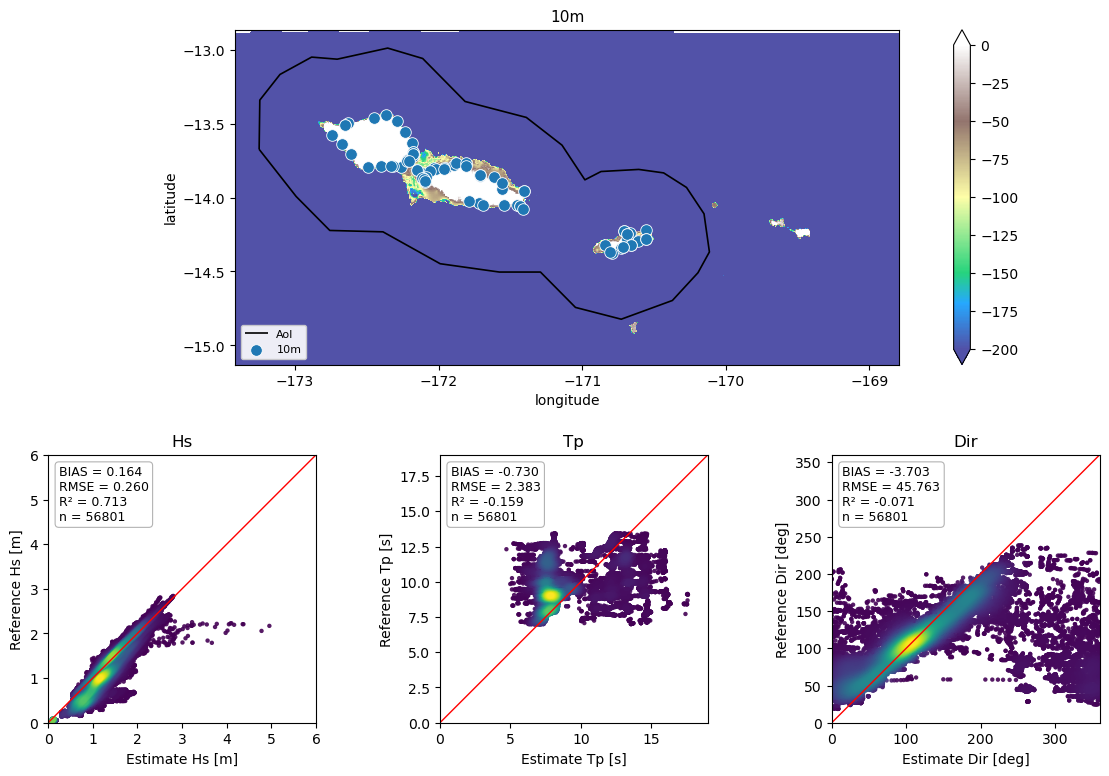

In [8]:
result.plot_all()
plt.show()